# Lecture Notes: Derivatives of Polynomials and Exponential Functions
*Stewart, **Calculus**, 9th ed., §3.1*

**Learning objectives.** By the end of this lecture you should be able to:
1. Differentiate constants, powers $x^n$, and polynomials without using the limit definition.
2. Use the Constant Multiple, Sum, and Difference Rules.
3. Explain why $\dfrac{d}{dx}(b^x) = f'(0)\,b^x$, and why the number $e$ makes $\dfrac{d}{dx}(e^x) = e^x$.
4. Find tangent lines, normal lines, and horizontal tangents.
5. Check every answer symbolically with **SymPy** and numerically with **NumPy**.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import Math, display

sp.init_printing()
x, t, h, n = sp.symbols("x t h n")

## 1. Why we need rules

By definition,
$$f'(x) = \lim_{h\to 0}\frac{f(x+h) - f(x)}{h}.$$

Computing this limit every time is slow. In this lecture we use the definition **once** for each basic type of function. The results become rules we can apply right away.

The helper below compares a derivative found by hand with SymPy's answer and displays the result.

In [2]:
def check(f, by_hand, var=x):
    """Display d/dvar f = by_hand and confirm it agrees with SymPy."""
    ok = sp.simplify(sp.diff(f, var) - by_hand) == 0
    display(Math(rf"\frac{{d}}{{d{sp.latex(var)}}}\left({sp.latex(f)}\right) = {sp.latex(by_hand)}"))
    print("Agrees with SymPy:", ok)


def diff_from_definition(f, var=x):
    """Compute f'(var) as the limit of the difference quotient."""
    return sp.limit((f.subs(var, var + h) - f) / h, h, 0)

## 2. Constant functions and the Power Rule

### Constant functions
The graph of $f(x) = c$ is a horizontal line, so its slope is $0$ everywhere:
$$\boxed{\frac{d}{dx}(c) = 0}$$
From the definition: $\dfrac{c - c}{h} = 0$ for every $h \neq 0$, so the limit is $0$.

### Powers with positive integer exponents
Look at the first few cases, using the limit definition:

| $f(x)$ | $x$ | $x^2$ | $x^3$ | $x^4$ |
|---|---|---|---|---|
| $f'(x)$ | $1$ | $2x$ | $3x^2$ | $4x^3$ |

The pattern is clear:

**The Power Rule.** If $n$ is a positive integer, then
$$\boxed{\frac{d}{dx}(x^n) = n\,x^{n-1}}$$

**Proof.** Use the binomial theorem to expand $(x+h)^n$:
$$\frac{(x+h)^n - x^n}{h} = \frac{\left[x^n + n x^{n-1}h + \binom{n}{2}x^{n-2}h^2 + \cdots + h^n\right] - x^n}{h}
= n x^{n-1} + \binom{n}{2}x^{n-2}h + \cdots + h^{n-1}.$$
Every term after the first contains a factor of $h$, so it goes to $0$ as $h\to 0$. That leaves $n x^{n-1}$. $\blacksquare$

The table above, computed from the definition:

In [3]:
for k in range(1, 6):
    display(Math(rf"\frac{{d}}{{dx}}\left(x^{k}\right) = {sp.latex(diff_from_definition(x**k))}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### The general Power Rule
The rule holds for **every real number** $n$:
$$\boxed{\frac{d}{dx}(x^n) = n\,x^{n-1}, \qquad n \in \mathbb{R}}$$
(Stewart proves the general case later with logarithmic differentiation, in §3.6.)

**Example 1.**
- (a) $\dfrac{d}{dx}\left(\dfrac{1}{x^2}\right) = \dfrac{d}{dx}\left(x^{-2}\right) = -2x^{-3} = -\dfrac{2}{x^3}$
- (b) $\dfrac{d}{dx}\left(\sqrt[3]{x^2}\right) = \dfrac{d}{dx}\left(x^{2/3}\right) = \tfrac{2}{3}x^{-1/3}$
- (c) $\dfrac{d}{dx}\left(x^{\pi}\right) = \pi x^{\pi - 1}$

**Tip:** before you differentiate, rewrite roots and reciprocals as powers.

In [4]:
check(1 / x**2, -2 / x**3)
check(x**sp.Rational(2, 3), sp.Rational(2, 3) * x**sp.Rational(-1, 3))
check(x**sp.pi, sp.pi * x**(sp.pi - 1))

<IPython.core.display.Math object>

Agrees with SymPy: True


<IPython.core.display.Math object>

Agrees with SymPy: True


<IPython.core.display.Math object>

Agrees with SymPy: True


**Example 2 (tangent and normal lines).** Find the tangent line and the normal line to $y = x\sqrt{x}$ at the point $(1, 1)$.

*By hand.* $y = x^{3/2}$, so $y' = \tfrac{3}{2}x^{1/2}$. At $x = 1$ the slope is $m = \tfrac32$.
- Tangent: $y - 1 = \tfrac32(x - 1)$, so $y = \tfrac32 x - \tfrac12$.
- The normal line is perpendicular to the tangent, so its slope is $-1/m = -\tfrac23$. Normal: $y - 1 = -\tfrac23(x-1)$, so $y = -\tfrac23 x + \tfrac53$.

<IPython.core.display.Math object>

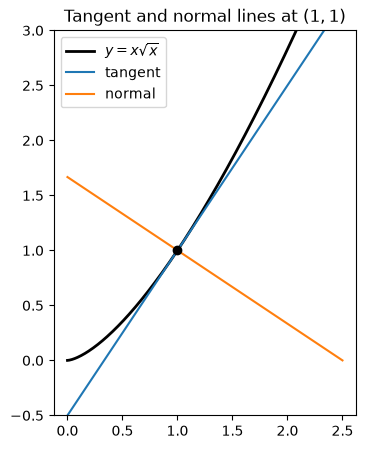

In [5]:
y = x * sp.sqrt(x)
m = sp.diff(y, x).subs(x, 1)
tangent = sp.expand(1 + m * (x - 1))
normal = sp.expand(1 - (x - 1) / m)
display(Math(rf"\text{{tangent: }} y = {sp.latex(tangent)}, \qquad \text{{normal: }} y = {sp.latex(normal)}"))

xs = np.linspace(0, 2.5, 300)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(xs, xs**1.5, "k", lw=2, label=r"$y = x\sqrt{x}$")
ax.plot(xs, 1.5 * xs - 0.5, lw=1.5, label="tangent")
ax.plot(xs, -2 / 3 * xs + 5 / 3, lw=1.5, label="normal")
ax.plot(1, 1, "ko")
ax.set_aspect("equal")
ax.set_ylim(-0.5, 3)
ax.legend()
ax.set_title(r"Tangent and normal lines at $(1,1)$")
plt.show()

## 3. New derivatives from old

Suppose $c$ is a constant and $f$ and $g$ are differentiable.

| Rule | Formula |
|---|---|
| Constant Multiple | $\dfrac{d}{dx}\big[c\,f(x)\big] = c\,\dfrac{d}{dx}f(x)$ |
| Sum | $\dfrac{d}{dx}\big[f(x) + g(x)\big] = \dfrac{d}{dx}f(x) + \dfrac{d}{dx}g(x)$ |
| Difference | $\dfrac{d}{dx}\big[f(x) - g(x)\big] = \dfrac{d}{dx}f(x) - \dfrac{d}{dx}g(x)$ |

**Proof of the Sum Rule.** Let $F = f + g$. Then
$$F'(x) = \lim_{h\to0}\frac{[f(x+h)+g(x+h)] - [f(x)+g(x)]}{h}
= \lim_{h\to0}\frac{f(x+h)-f(x)}{h} + \lim_{h\to0}\frac{g(x+h)-g(x)}{h} = f'(x) + g'(x).$$
The limit of a sum is the sum of the limits, and both limits exist because $f$ and $g$ are differentiable. $\blacksquare$

The Sum Rule extends to any finite number of terms. Together with the Power Rule, this means **we can differentiate any polynomial term by term.**

**Example 3.**
$$\frac{d}{dx}\left(x^8 + 12x^5 - 4x^4 + 10x^3 - 6x + 5\right) = 8x^7 + 60x^4 - 16x^3 + 30x^2 - 6.$$

In [6]:
p = x**8 + 12*x**5 - 4*x**4 + 10*x**3 - 6*x + 5
check(p, 8*x**7 + 60*x**4 - 16*x**3 + 30*x**2 - 6)

<IPython.core.display.Math object>

Agrees with SymPy: True


**Example 4 (horizontal tangents).** Find the points on $y = x^4 - 6x^2 + 4$ where the tangent line is horizontal.

*By hand.* A horizontal tangent has slope $0$:
$$y' = 4x^3 - 12x = 4x(x^2 - 3) = 0 \quad\Longrightarrow\quad x = 0,\ \pm\sqrt3.$$
The points are $(0, 4)$, $(\sqrt3, -5)$, and $(-\sqrt3, -5)$.

<IPython.core.display.Math object>

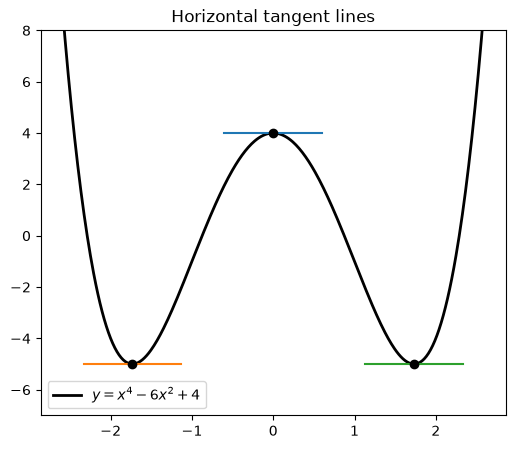

In [7]:
y = x**4 - 6*x**2 + 4
crit = sp.solve(sp.diff(y, x), x)
pts = [(c, y.subs(x, c)) for c in crit]
display(Math(r"\text{Horizontal tangents at } " + ", ".join(sp.latex(pt) for pt in pts)))

xs = np.linspace(-2.6, 2.6, 400)
f = sp.lambdify(x, y, "numpy")
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(xs, f(xs), "k", lw=2, label=r"$y = x^4 - 6x^2 + 4$")
for cx, cy in pts:
    cx, cy = float(cx), float(cy)
    ax.plot([cx - 0.6, cx + 0.6], [cy, cy], lw=1.5)
    ax.plot(cx, cy, "ko")
ax.set_ylim(-7, 8)
ax.legend()
ax.set_title("Horizontal tangent lines")
plt.show()

## 4. Exponential functions

Let $f(x) = b^x$ with $b > 0$. The definition gives
$$f'(x) = \lim_{h\to0}\frac{b^{x+h} - b^x}{h} = \lim_{h\to0}\frac{b^x\,b^h - b^x}{h} = b^x \lim_{h\to0}\frac{b^h - 1}{h}.$$
The remaining limit does not depend on $x$. It is exactly $f'(0)$, the slope of $y = b^x$ at $x = 0$. So
$$\boxed{\frac{d}{dx}\left(b^x\right) = f'(0)\,b^x, \qquad f'(0) = \lim_{h\to0}\frac{b^h-1}{h}}$$

**An exponential function's rate of change is proportional to the function itself.** We still need the constant $f'(0)$. Let's estimate it numerically for $b = 2$ and $b = 3$:

In [8]:
hs = np.array([0.1, 0.01, 0.001, 0.0001])
print(f"{'h':>8} {'(2^h-1)/h':>12} {'(3^h-1)/h':>12}")
for hv in hs:
    print(f"{hv:>8} {(2**hv - 1) / hv:>12.6f} {(3**hv - 1) / hv:>12.6f}")

       h    (2^h-1)/h    (3^h-1)/h
     0.1     0.717735     1.161232
    0.01     0.695555     1.104669
   0.001     0.693387     1.099216
  0.0001     0.693171     1.098673


So $f'(0) \approx 0.69$ when $b = 2$, and $f'(0) \approx 1.10$ when $b = 3$. Somewhere between $2$ and $3$ there is a base for which $f'(0) = 1$ exactly.

**Definition of $e$.** $e$ is the number such that
$$\boxed{\lim_{h\to0}\frac{e^h - 1}{h} = 1}$$
Geometrically, $y = e^x$ is the only exponential function whose tangent line at $(0,1)$ has slope exactly $1$. Its value is $e \approx 2.71828$.

**Derivative of the natural exponential function.**
$$\boxed{\frac{d}{dx}\left(e^x\right) = e^x}$$
$e^x$ is its own derivative: at every point, the slope of the graph equals the height of the graph.

(In §3.6 we'll see that $f'(0) = \ln b$, so $\dfrac{d}{dx}(b^x) = b^x \ln b$. Check: $\ln 2 \approx 0.693$ and $\ln 3 \approx 1.099$.)

In [9]:
for b in [2, 3, sp.E]:
    lim = sp.limit((b**h - 1) / h, h, 0)
    display(Math(rf"b = {sp.latex(b)}: \quad \lim_{{h\to0}}\frac{{b^h - 1}}{{h}} = {sp.latex(lim)} \approx {float(lim):.5f}"))

check(sp.exp(x), sp.exp(x))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Agrees with SymPy: True


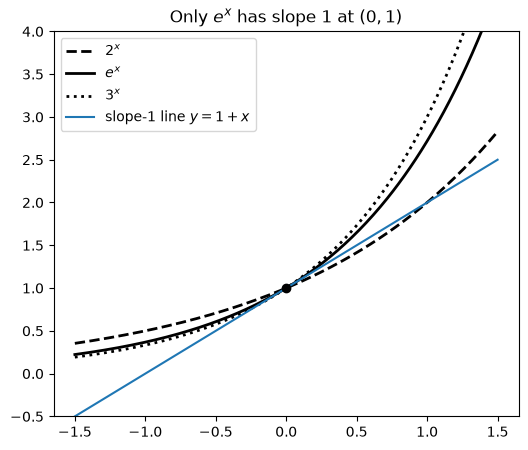

In [10]:
xs = np.linspace(-1.5, 1.5, 300)
fig, ax = plt.subplots(figsize=(6, 5))
for b, ls in [(2, "--"), (np.e, "-"), (3, ":")]:
    label = r"$e^x$" if b == np.e else rf"${b}^x$"
    ax.plot(xs, b**xs, "k", ls=ls, lw=2, label=label)
ax.plot(xs, 1 + xs, lw=1.5, label=r"slope-1 line $y = 1 + x$")
ax.plot(0, 1, "ko")
ax.set_ylim(-0.5, 4)
ax.legend()
ax.set_title(r"Only $e^x$ has slope $1$ at $(0,1)$")
plt.show()

**Example 5.** If $f(x) = e^x - x$, find $f'$ and $f''$.

*By hand.* $f'(x) = e^x - 1$ and $f''(x) = e^x$. Since $f''(x) > 0$ for all $x$, $f'$ is always increasing. (Note that $f'(0) = 0$: the graph has a horizontal tangent at $(0, 1)$.)

In [11]:
f = sp.exp(x) - x
check(f, sp.exp(x) - 1)
check(sp.diff(f, x), sp.exp(x))

<IPython.core.display.Math object>

Agrees with SymPy: True


<IPython.core.display.Math object>

Agrees with SymPy: True


**Example 6.** At what point on $y = e^x$ is the tangent line parallel to $y = 2x$?

*By hand.* Parallel lines have equal slopes, so we need $y' = e^x = 2$. That gives $x = \ln 2$, and $y = e^{\ln 2} = 2$. The point is $(\ln 2,\ 2)$.

In [12]:
sol = sp.solve(sp.Eq(sp.diff(sp.exp(x), x), 2), x)
display(Math(rf"x = {sp.latex(sol[0])}, \quad y = {sp.latex(sp.exp(sol[0]))}"))

<IPython.core.display.Math object>

## 5. A numerical sanity check

Symbolic checks can hide algebra slips if we type the wrong function. As an independent check, we compare each by-hand derivative with a **central difference** $\dfrac{f(x+h) - f(x-h)}{2h}$ at many points.

In [13]:
def numeric_check(f, fprime, a=0.2, b=3.0, step=1e-5):
    fn, dfn = sp.lambdify(x, f, "numpy"), sp.lambdify(x, fprime, "numpy")
    xs = np.linspace(a, b, 200)
    approx = (fn(xs + step) - fn(xs - step)) / (2 * step)
    exact = dfn(xs)
    return np.max(np.abs(approx - exact)) / np.max(np.abs(exact))

tests = {
    r"x\sqrt{x}": (x * sp.sqrt(x), sp.Rational(3, 2) * sp.sqrt(x)),
    r"x^8 + 12x^5 - \cdots": (p, 8*x**7 + 60*x**4 - 16*x**3 + 30*x**2 - 6),
    r"x^4 - 6x^2 + 4": (x**4 - 6*x**2 + 4, 4*x**3 - 12*x),
    r"e^x - x": (sp.exp(x) - x, sp.exp(x) - 1),
}
for name, (f, fp) in tests.items():
    rel = numeric_check(f, fp)
    display(Math(rf"{name}: \quad \text{{relative error}} \approx {rel:.1e}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 6. Practice problems

Try these by hand first, then run the cell below to check.

1. $f(x) = 5x^4 - 3x^{2/3} + \dfrac{7}{x}$
2. $y = \dfrac{x^2 + 4x + 3}{\sqrt x}$ (*simplify first*)
3. $y = 3e^x + \dfrac{4}{\sqrt[3]{x}}$
4. Find the tangent and normal lines to $y = x^4 + 2e^x$ at $(0, 2)$.
5. For what values of $x$ does $f(x) = x^3 + 3x^2 + x + 3$ have a horizontal tangent?
6. For what value of $a$ does the tangent line to $y = e^x$ at $x = a$ pass through the origin?

In [14]:
problems = [
    5*x**4 - 3*x**sp.Rational(2, 3) + 7/x,
    (x**2 + 4*x + 3) / sp.sqrt(x),
    3*sp.exp(x) + 4*x**sp.Rational(-1, 3),
]
for i, f in enumerate(problems, 1):
    df = sp.diff(f, x)
    df = sp.factor(sp.simplify(df)) if i == 2 else df
    display(Math(rf"\text{{{i}.}}\quad \frac{{d}}{{dx}}\left({sp.latex(f)}\right) = {sp.latex(df)}"))

# 4. tangent and normal lines at (0, 2)
y = x**4 + 2*sp.exp(x)
m = sp.diff(y, x).subs(x, 0)
display(Math(rf"\text{{4.}}\quad \text{{tangent: }} y = {sp.latex(2 + m*x)}, \qquad \text{{normal: }} y = {sp.latex(2 - x/m)}"))

# 5. horizontal tangents
f = x**3 + 3*x**2 + x + 3
display(Math(rf"\text{{5.}}\quad x = {sp.latex(sp.solve(sp.diff(f, x), x))}"))

# 6. tangent at x = a is y = e^a + e^a (x - a); set x = 0, y = 0
a = sp.symbols("a")
display(Math(rf"\text{{6.}}\quad a = {sp.latex(sp.solve(sp.exp(a) + sp.exp(a) * (0 - a), a))}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Summary

| Function | Derivative | Rule |
|---|---|---|
| $c$ | $0$ | Constant |
| $x^n$ | $n x^{n-1}$ | Power ($n \in \mathbb{R}$) |
| $c\,f$ | $c\,f'$ | Constant Multiple |
| $f \pm g$ | $f' \pm g'$ | Sum / Difference |
| $b^x$ | $f'(0)\,b^x = b^x \ln b$ | Exponential |
| $e^x$ | $e^x$ | Natural exponential |

**Key ideas.**
- Rewrite roots and reciprocals as powers before you differentiate.
- Polynomials are differentiated term by term.
- $e$ is defined so that $e^x$ has slope $1$ at $x = 0$. That is what makes $(e^x)' = e^x$.
- Tangent line at $x = a$: $y = f(a) + f'(a)(x - a)$. The normal line has slope $-1/f'(a)$.

**Next:** [§3.2 The Product and Quotient Rules](product_and_quotient_rules.ipynb).